# Entrenamiento y Exportación de Modelo YOLO para Detección

Este cuaderno implementa el flujo de trabajo para descargar un conjunto de datos de detección desde Roboflow, entrenar un modelo YOLOv10, validar su rendimiento, realizar inferencias y exportar el modelo a formato TorchScript para su uso posterior.

## Descripción General
- **Descarga de datos**: Se obtiene un conjunto de datos desde Roboflow.
- **Entrenamiento**: Se entrena un modelo YOLOv10 con el conjunto de datos descargado.
- **Validación**: Se evalúa el rendimiento del modelo en un conjunto de validación.
- **Inferencia**: Se realiza una inferencia visual en imágenes de prueba.
- **Exportación**: Se exporta el modelo entrenado a formato TorchScript.

In [2]:
%%capture
!pip install ultralytics roboflow

In [3]:
!python -V
!pip list | grep torch
!pip list | grep ultralytics

Python 3.11.13
pytorch-ignite                        0.5.2
pytorch-lightning                     2.5.2
torch                                 2.6.0+cu124
torchao                               0.10.0
torchaudio                            2.6.0+cu124
torchdata                             0.11.0
torchinfo                             1.8.0
torchmetrics                          1.7.3
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.21.0+cu124
ultralytics                           8.3.169
ultralytics-thop                      2.0.14


In [4]:
# -*- coding: utf-8 -*-
# Importación de bibliotecas necesarias
import os
import yaml
import gdown
import wandb
import shutil
import requests
import ipywidgets as widgets
import cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from roboflow import Roboflow
from IPython.display import display, Image, clear_output
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import torch
import torchvision
import torch.nn as nn
from torchvision.io import ImageReadMode
import torchvision.transforms.functional as TF

# Deshabilitar Weights & Biases para evitar registros innecesarios
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Descarga y Configuración del Conjunto de Datos

Se descarga un conjunto de datos de detección de desde Roboflow y se configura un archivo YAML para definir las rutas de las imágenes y las clases.

In [5]:
# Descarga del conjunto de datos desde Roboflow
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="TU_API_KEY_AQUI")
project = rf.workspace("detection-dg8e4").project("coffee-beans-scmes")
version = project.version(9)
dataset = version.download("yolov8")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to COFFEE-BEANS-9 in yolov8:: 100%|██████████| 3984/3984 [00:02<00:00, 1536.54it/s]


In [6]:
# Configuración del archivo YAML para el conjunto de datos
data_config = {
    'path': '/kaggle/working/COFFEE-BEANS-9',  # Ruta base del conjunto de datos
    'train': 'train/images',  # Carpeta de imágenes de entrenamiento
    'val': 'valid/images',    # Carpeta de imágenes de validación
    'test': 'test/images',    # Carpeta de imágenes de prueba
    'names': {0: 'Maduro', 1: 'Maduro defectuoso', 2: 'No maduro'},  # Nombres de las clases
    'roboflow': {  # Metadatos del proyecto
        'license': 'CC BY 4.0',
        'project': 'coffee-beans-scmes',
        'url': 'https://universe.roboflow.com/detection-dg8e4/coffee-beans-scmes/dataset/9',
        'version': '9',
        'workspace': 'detection-dg8e4'
    }
}

# Guardar la configuración en un archivo YAML
yaml_path = '/kaggle/working/COFFEE-BEANS-9/data_fix.yaml'
with open(yaml_path, 'w') as yaml_file:
    yaml.dump(data_config, yaml_file, default_flow_style=False)
print(f"Archivo YAML creado en: {yaml_path}")

Archivo YAML creado en: /kaggle/working/COFFEE-BEANS-9/data_fix.yaml


## Entrenamiento del Modelo YOLOv10

Se carga un modelo YOLOv10 preentrenado y se entrena con el conjunto de datos configurado.

In [7]:
# Cargar el modelo YOLOv10 preentrenado
model = YOLO('yolov8n.pt')  # Modelo base pequeño para detección

# Entrenar el modelo con los parámetros especificados
results = model.train(
    data=yaml_path,  # Ruta al archivo YAML de configuración
    epochs=1,      # Número de épocas de entrenamiento
    imgsz=640,       # Tamaño de las imágenes de entrada
    device=[0, 1]    # Usar múltiples GPUs si están disponibles
)

print("Entrenamiento completado.")

100%|██████████| 6.25M/6.25M [00:00<00:00, 82.4MB/s]


Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
                                                        CUDA:1 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/COFFEE-BEANS-9/data_fix.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, o

100%|██████████| 755k/755k [00:00<00:00, 17.4MB/s]


Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 70.3MB/s]


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4237.2±1112.1 MB/s, size: 1115.3 KB)


... (4 outputs left out)

        1/1      1.08G      1.195      2.677      1.194         17        640: 100%|██████████| 108/108 [00:30<00:00,  3.52it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 9/9 [00:02<00:00,  3.22it/s]
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all        141        141      0.917      0.728      0.936      0.676

1 epochs completed in 0.010 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/train/weights/best.pt, 6.2MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
                                                        CUDA:1 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 9/9 [00:01<00:00,  5.00it/s]
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all        141        141      0.917       0.73      0.936      0.675
                Maduro         54         54      0.827      0.963      0.941      0.773
     Maduro defectuoso         37         37      0.952      0.535      0.901      0.607
             No maduro         50         50      0.972      0.691      0.965      0.644
Speed: 0.3ms preprocess, 2.4ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to runs/detect/train
Entrenamiento completado.


## Validación del Modelo

Se valida el modelo entrenado utilizando el conjunto de validación y se visualizan métricas como la matriz de confusión y la curva F1.

Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1062.3±240.2 MB/s, size: 111.4 KB)


val: Scanning /kaggle/working/COFFEE-BEANS-9/valid/labels.cache... 141 images, 0 backgrounds, 0 corrupt: 100%|██████████| 141/141 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 9/9 [00:02<00:00,  4.31it/s]
invalid value encountered in less
invalid value encountered in less


                   all        141        141          0          0          0          0
                Maduro         54         54          0          0          0          0
     Maduro defectuoso         37         37          0          0          0          0
             No maduro         50         50          0          0          0          0
Speed: 1.0ms preprocess, 5.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to runs/detect/val


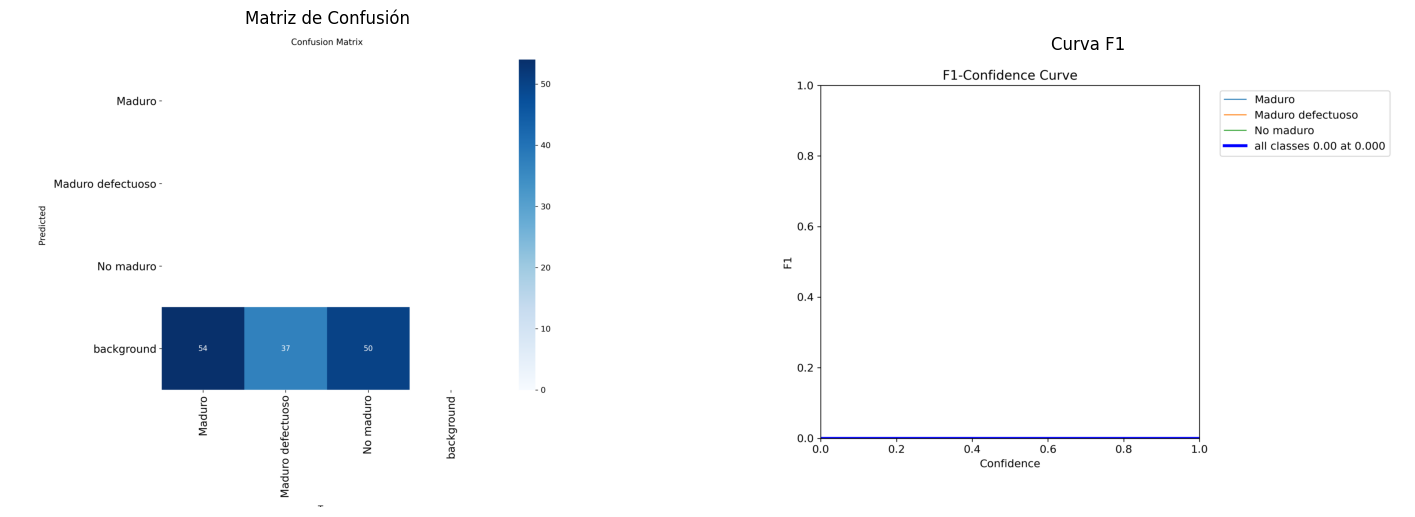

In [8]:
# Cargar el modelo entrenado
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')

# Realizar validación del modelo
validation_results = model.val(
    data=yaml_path,  # Ruta al archivo YAML
    imgsz=640,       # Tamaño de las imágenes
    batch=16,        # Tamaño del lote
    conf=0.5,        # Umbral de confianza
    iou=0.6,         # Umbral de IoU
    device='0'       # Dispositivo GPU
)

# Visualizar métricas de validación
confusion_matrix = mpimg.imread("/kaggle/working/runs/detect/val/confusion_matrix.png")
f1_curve = mpimg.imread("/kaggle/working/runs/detect/val/BoxF1_curve.png")

# Mostrar imágenes de métricas
fig, axis = plt.subplots(1, 2, figsize=(18, 8))
axis[0].imshow(confusion_matrix)
axis[0].set_title('Matriz de Confusión')
axis[0].axis('off')
axis[1].imshow(f1_curve)
axis[1].set_title('Curva F1')
axis[1].axis('off')
plt.show()

## Inspección Visual de Resultados

Se realiza una inferencia en imágenes de prueba y se visualizan los resultados con un control deslizante interactivo.

In [9]:
# Ruta de la carpeta con imágenes de prueba
image_folder_path = '/kaggle/working/COFFEE-BEANS-9/test/images'

# Obtener lista de imágenes (formatos soportados: png, jpg, jpeg)
image_paths = [os.path.join(image_folder_path, img) for img in os.listdir(image_folder_path) 
               if img.endswith(('.png', '.jpg', '.jpeg'))]
num_images = len(image_paths)

# Crear un control deslizante para seleccionar imágenes
slider = widgets.IntSlider(min=0, max=num_images-1, description='Imagen:')
display(slider)

IntSlider(value=0, description='Imagen:', max=116)


image 1/1 /kaggle/working/COFFEE-BEANS-9/test/images/IMG_20210314_171054049_jpg.rf.82523801d25ccac3974f4d6f94ceb693.jpg: 480x640 (no detections), 34.3ms
Speed: 2.5ms preprocess, 34.3ms inference, 0.8ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/detect/predict


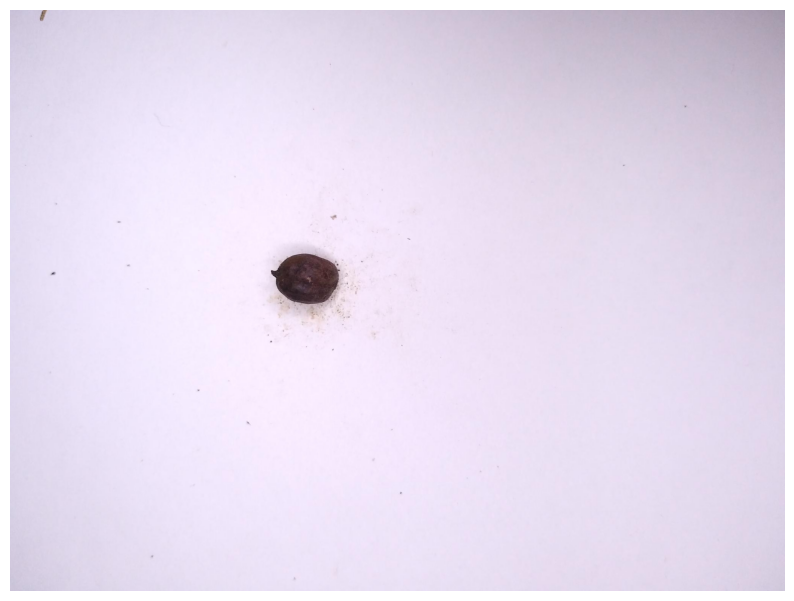

In [10]:
# Función para actualizar la visualización al cambiar el slider
def update_image(image_path, indx):
    
    # Obtener la imagen seleccionada
    imagen_dir = image_path[indx]
    
    # Realizar inferencia con el modelo
    model.predict(imagen_dir, save=True, imgsz=640, conf=0.5, show_boxes=True, show_labels=True)
    
    # Ruta de la imagen con las detecciones
    image_path = f"/kaggle/working/runs/detect/predict/{os.path.basename(imagen_dir)}"
    
    # Mostrar la imagen con detecciones
    image = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

# Mostrar la imagen al cargar
update_image(image_paths, slider.value)

## Exportación del Modelo a TorchScript

Se exporta el modelo entrenado a formato TorchScript y se implementan funciones para cargar el modelo, preprocesar imágenes y realizar inferencias.

In [11]:
# Exportar el modelo a formato TorchScript
model = YOLO("/kaggle/working/runs/detect/train/weights/best.pt")
model.export(
    format='torchscript',  # Formato de exportación
    imgsz=640,            # Tamaño de las imágenes
    data=yaml_path,        # Ruta al archivo YAML
    half=False
)
print("Modelo exportado a TorchScript.")

Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.6.0+cu124 CPU (Intel Xeon 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.9 MB)

TorchScript: starting export with torch 2.6.0+cu124...
TorchScript: export success ✅ 1.9s, saved as '/kaggle/working/runs/detect/train/weights/best.torchscript' (11.9 MB)

Export complete (2.3s)
Results saved to /kaggle/working/runs/detect/train/weights
Predict:         yolo predict task=detect model=/kaggle/working/runs/detect/train/weights/best.torchscript imgsz=640  
Validate:        yolo val task=detect model=/kaggle/working/runs/detect/train/weights/best.torchscript imgsz=640 data=/kaggle/working/COFFEE-BEANS-9/data_fix.yaml  
Vi

In [12]:
# Función para cargar el modelo TorchScript
def load_torchscript_model(model_path, device='cpu'):
    """Carga un modelo en formato TorchScript.
    
    Args:
        model_path (str): Ruta al archivo del modelo.
        device (str): Dispositivo para cargar el modelo ('cpu' o 'cuda').
    Returns:
        model: Modelo cargado en modo evaluación.
    """
    model = torch.jit.load(model_path, map_location=device)
    model.eval()
    print(f"Modelo cargado desde {model_path} en {device}")
    return model

# Función para preprocesar imágenes
def preprocess_image(image_path, input_size=(640, 640)):
    """Preprocesa una imagen para inferencia con YOLO.
    
    Args:
        image_path (str): Ruta a la imagen.
        input_size (tuple): Tamaño al que redimensionar la imagen.
    Returns:
        tuple: Tensor de la imagen preprocesada y la imagen original.
    """
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, input_size)
    img_tensor = torch.from_numpy(img_resized).float().permute(2, 0, 1).unsqueeze(0) / 255.0
    return img_tensor, img

# Función para ejecutar inferencia
def run_inference(model, input_tensor, device='cpu'):
    """Ejecuta inferencia con el modelo TorchScript.
    
    Args:
        model: Modelo cargado.
        input_tensor: Tensor de entrada preprocesado.
        device (str): Dispositivo para la inferencia.
    Returns:
        outputs: Resultados de la inferencia.
    """
    input_tensor = input_tensor.to(device)
    with torch.no_grad():
        if device != 'cpu':
            start_time = torch.cuda.Event(enable_timing=True)
            end_time = torch.cuda.Event(enable_timing=True)
            start_time.record()
            outputs = model(input_tensor)
            end_time.record()
            torch.cuda.synchronize()
            inference_time = start_time.elapsed_time(end_time)
        else:
            import time
            start = time.time()
            outputs = model(input_tensor)
            inference_time = (time.time() - start) * 1000
    print(f"Tiempo de inferencia: {inference_time:.2f} ms")
    return outputs

# Función para visualizar detecciones
def visualize_detections(image_path, detections_tensor, confidence_threshold=0.5, output_path=None):
    """Visualiza las detecciones del modelo YOLO en una imagen."""
    # Cargar imagen original
    img = cv2.imread(image_path)
    height, width = img.shape[:2]
    
    # Tomar tensor adecuado
    detections = detections_tensor[0] if len(detections_tensor.shape) == 3 else detections_tensor

    # Filtrar por confianza
    valid_detections = detections[detections[:, 4] >= confidence_threshold]

    # Nombres reales de clases (ajusta si usas otro orden)
    class_names = ['Maduro', 'Maduro defectuoso', 'No maduro']

    # Colores
    np.random.seed(42)
    colors = [(np.random.randint(0,255), np.random.randint(0,255), np.random.randint(0,255)) for _ in range(len(class_names))]

    # Dibujar
    # Dibujar detecciones en la imagen
    for detection in valid_detections:
        x1, y1, x2, y2, conf, cls_id = detection[:6]
    
        x1, y1, x2, y2, cls_id = int(x1), int(y1), int(x2), int(y2), int(cls_id)
        color = colors[cls_id % len(colors)]
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        label = f'Clase {cls_id}: {conf:.2f}'
        cv2.putText(img, label, (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    
    # Guardar la imagen si se proporciona una ruta
    if output_path:
        cv2.imwrite(output_path, img)
    print(f'Detecciones mostradas: {len(valid_detections)}')


In [13]:
# Ejemplo de uso
model = load_torchscript_model('/kaggle/working/runs/detect/train/weights/best.torchscript')

Modelo cargado desde /kaggle/working/runs/detect/train/weights/best.torchscript en cpu


In [14]:
input_tensor, original_img = preprocess_image('/kaggle/working/COFFEE-BEANS-9/test/images/IMG_20210314_141644242_jpg.rf.eadbd74ac97003e54404d62c4d91c0de.jpg')

outputs = run_inference(model, input_tensor)
visualize_detections(
    "/kaggle/working/COFFEE-BEANS-9/test/images/IMG_20210314_141644242_jpg.rf.eadbd74ac97003e54404d62c4d91c0de.jpg",
    outputs,
    confidence_threshold=0.5,
    output_path="result.jpg"
)

Tiempo de inferencia: 185.33 ms
Detecciones mostradas: 4
